In [1]:
from __future__ import annotations

import pandas as pd


# ---------------------------------------------------------------------------
# Load the exported DFG parquets back into pm4py-shaped objects
# ---------------------------------------------------------------------------

def load_dfg(path_prefix: str):
    """Read dfg_<cf>.{edges,nodes}.parquet -> (dfg, starts, ends).
    path_prefix is the part WITHOUT the .edges/.nodes suffix, e.g.
    'nets/dfg_s2_io_flip'."""
    e = pd.read_parquet(path_prefix + ".edges.parquet")
    n = pd.read_parquet(path_prefix + ".nodes.parquet")
    dfg = {(r.src, r.dst): float(r.weight) for r in e.itertuples(index=False)}
    starts = {r.activity: float(r.start) for r in n.itertuples(index=False) if r.start > 0}
    ends = {r.activity: float(r.end) for r in n.itertuples(index=False) if r.end > 0}
    return dfg, starts, ends


# ---------------------------------------------------------------------------
# DFG views
# ---------------------------------------------------------------------------

def view_dfg(dfg: dict, starts: dict, ends: dict, fmt: str = "png"):
    """Rich DFG view via pm4py (needs Graphviz). Renders inline in a notebook."""
    import pm4py
    pm4py.view_dfg(dfg, dict(starts), dict(ends), format=fmt)


def view_dfg_mpl(dfg: dict, starts: dict, ends: dict, figsize=(9, 7),
                 layer_from_label=True):
    """Graphviz-free DFG view with matplotlib + networkx. Nodes are laid out
    by layer if activity labels look like 'L03.F11' (Part 2's convention),
    else by a spring layout. Edge width ~ weight; start/end nodes highlighted.
    Returns the matplotlib Axes."""
    import matplotlib.pyplot as plt
    import networkx as nx

    g = nx.DiGraph()
    for (a, b), w in dfg.items():
        g.add_edge(a, b, weight=w)

    if layer_from_label and all("." in n for n in g.nodes()):
        # x = layer, y = spread within layer
        layers = {}
        for n in g.nodes():
            L = int(n.split(".")[0][1:])
            layers.setdefault(L, []).append(n)
        pos = {}
        for L, nodes in layers.items():
            for i, n in enumerate(sorted(nodes)):
                pos[n] = (L, i - (len(nodes) - 1) / 2)
    else:
        pos = nx.spring_layout(g, seed=0)

    weights = [g[u][v]["weight"] for u, v in g.edges()]
    wmax = max(weights) if weights else 1.0
    widths = [0.5 + 3.5 * w / wmax for w in weights]

    node_colors = []
    for n in g.nodes():
        if n in starts and n in ends:
            node_colors.append("#c8a2c8")
        elif n in starts:
            node_colors.append("#8ecae6")
        elif n in ends:
            node_colors.append("#ffb703")
        else:
            node_colors.append("#e0e0e0")

    fig, ax = plt.subplots(figsize=figsize)
    nx.draw_networkx_edges(g, pos, width=widths, edge_color="#888",
                           arrowsize=12, connectionstyle="arc3,rad=0.08", ax=ax)
    nx.draw_networkx_nodes(g, pos, node_color=node_colors, node_size=900,
                           edgecolors="#444", ax=ax)
    nx.draw_networkx_labels(g, pos, font_size=7, ax=ax)
    ax.set_xlabel("layer" if layer_from_label else "")
    ax.set_title("DFG (blue=start, orange=end, purple=both; width ~ weight)")
    ax.axis("off" if not layer_from_label else "on")
    plt.tight_layout()
    return ax


# ---------------------------------------------------------------------------
# Petri net view
# ---------------------------------------------------------------------------

def view_net(pnml_path: str, fmt: str = "png"):
    """Read a saved PNML and render the Petri net via pm4py (needs Graphviz)."""
    import pm4py
    net, im, fm = pm4py.read_pnml(pnml_path)
    pm4py.view_petri_net(net, im, fm, format=fmt)
    return net, im, fm


def save_net_image(pnml_path: str, out_path: str):
    """Render a saved PNML to an image file (png/svg by extension)."""
    import pm4py
    net, im, fm = pm4py.read_pnml(pnml_path)
    pm4py.save_vis_petri_net(net, im, fm, out_path)
    return out_path

In [7]:
dfg, s, e = load_dfg("../nets/dfg_abc_counterfactual")

<Axes: title={'center': 'DFG (blue=start, orange=end, purple=both; width ~ weight)'}, xlabel='layer'>

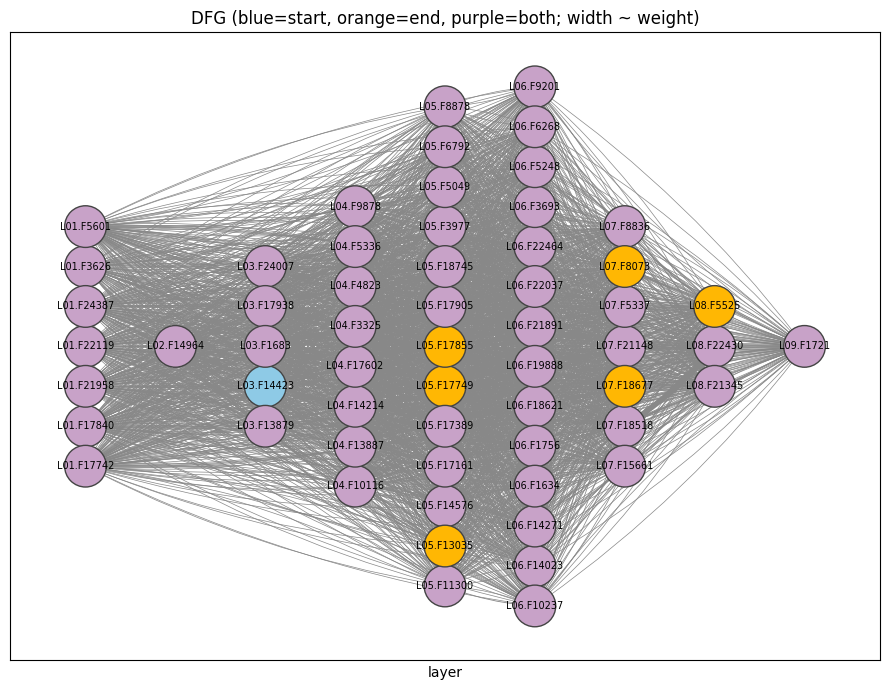

In [8]:
view_dfg_mpl(dfg, s, e)

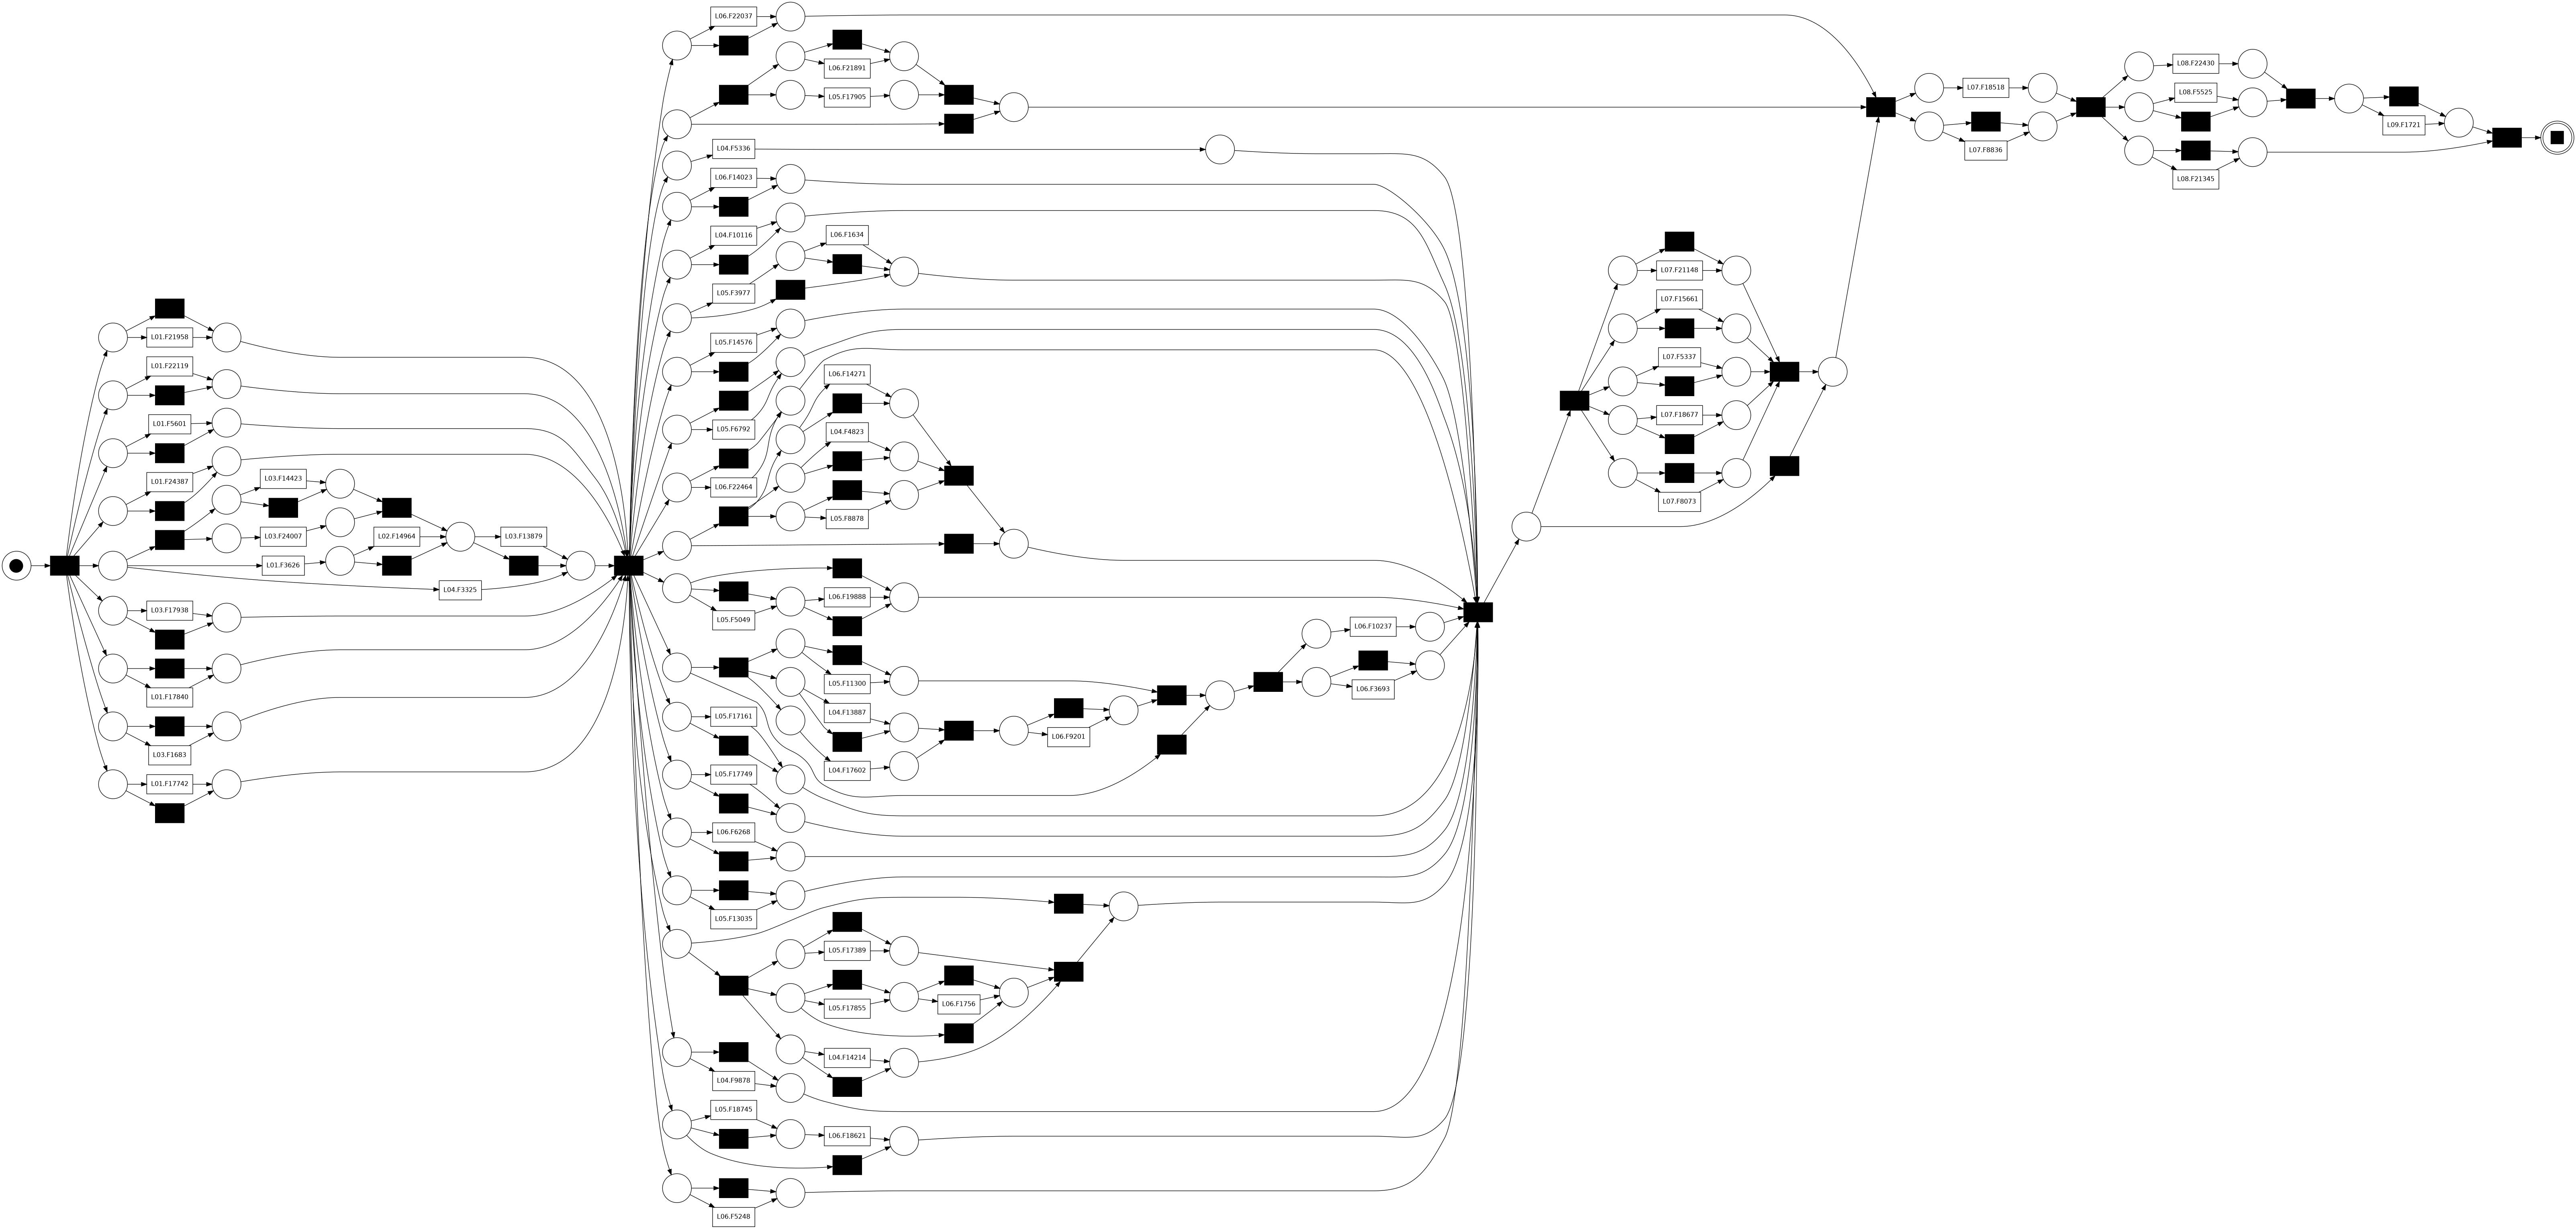

(places: [ p_10, p_100, p_101, p_102, p_103, p_104, p_105, p_106, p_107, p_108, p_109, p_11, p_110, p_111, p_112, p_113, p_114, p_115, p_117, p_118, p_119, p_12, p_120, p_121, p_122, p_124, p_125, p_126, p_127, p_128, p_129, p_13, p_14, p_15, p_16, p_17, p_18, p_19, p_20, p_21, p_22, p_23, p_24, p_25, p_26, p_27, p_29, p_30, p_31, p_32, p_33, p_34, p_35, p_36, p_38, p_39, p_4, p_40, p_41, p_42, p_43, p_44, p_45, p_46, p_47, p_48, p_49, p_5, p_50, p_51, p_52, p_53, p_54, p_55, p_56, p_57, p_58, p_59, p_6, p_60, p_61, p_62, p_63, p_64, p_65, p_66, p_67, p_68, p_69, p_7, p_70, p_71, p_72, p_73, p_74, p_75, p_76, p_77, p_78, p_79, p_8, p_80, p_81, p_82, p_83, p_84, p_85, p_86, p_87, p_88, p_89, p_9, p_90, p_92, p_93, p_94, p_96, p_97, p_98, p_99, sink, source ]
 transitions: [ (042b3754-9427-4e19-9a14-3e4ee61fa71f, 'L02.F14964'), (04fa18e8-850c-430b-aa1c-99dc023364d6, 'L06.F22037'), (0b39f1a7-1708-427b-bd91-c7c5bc53466a, 'L01.F17742'), (0cb6b6df-1a18-4cf3-8841-3931cefac832, 'L01.F21958'), 

In [6]:
view_net("../nets/net_abc_counterfactual.pnml")